<H1>COM2041 Lab 2: How to use and how not to use Symmetric Cryptography</H1>
<h2>Week 2, Spring Semester 2026</h2>


## 0. Exploring AES

To explore the operation of AES we will use several online tools:

An [ascii to hex converter](https://www.utilities-online.info/ascii-to-hex)

A [hex to binary converter](https://goteleport.com/resources/tools/hex-to-binary-converter/)

An [Online AES calculator](https://testprotect.com/appendix/AEScalc)

Initial tasks:

1. Convert the text "Meet me at noon." to Hex.  Use the AES calculator to encrypt the result with a key of your choice.

2. Find a key K and a block B such that B encrypted with K gives a ciphertext block consisting of all 0's.

3. Change a single bit in the key K, and then encrypt B.  How many <b>bits</b> have changed in the ciphertext (you will need to use the hex to binary converter)?  This is an illustration of <b>Confusion</b>: changing a single bit in the key should change many bits in the ciphertext (Slide 22).

4. Change a single bit in the block B, and then encrypt with the key K.  How many bits have changed in the ciphertext?  This is an illustration of <b>Diffusion</b>: changing a single bit in the plaintext should change many bits in the ciphertext (Slide 22).



## 1. The Advanced Encryption Standard (AES)
Start by installing the pycryptosome library and importing some useful modules.

In [ ]:
!pip install pycryptodome
!pip install requests pillow
from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes
from Crypto.Util.Padding import pad, unpad
import matplotlib.pyplot as plt
from collections import Counter
import io
import requests
import numpy as np
from PIL import Image

Let's get familiar with the pycryptodome library. In the cell below, we have instantiated the AES encryption scheme in Cipher-block Chaining (CBC) mode, with 16 bytes per block. You may find it useful to refer to the [documentation](https://pycryptodome.readthedocs.io/en/latest/src/cipher/aes.html) for this library. 

In [90]:
blocksize = 16 #consult the documentation to set the blocksize for AES
key = get_random_bytes(blocksize) #Set a valid key length for AES
iv = get_random_bytes(blocksize) #Set a valid key length for AES
cbc_encrypt = AES.new(key, AES.MODE_CBC,iv)
msg = b"Computer Security is really fun!"
ctxt = cbc_encrypt.encrypt(msg)

### Task 1.1
Decrypt the ciphertext!

In [91]:
#SOLUTION
cbc_decrypt = AES.new(key, AES.MODE_CBC,iv)
msg = cbc_decrypt.decrypt(ctxt)
print('plaintext:',msg)

plaintext: b'Computer Security is really fun!'


### Task 1.2: 
Change the message to be encrypted to anything of your choice until something goes wrong. What is happening? Our message is no longer an exact multiple of the blocksize, which means we cannot encrypt it. As we have learnt in lectures, this can be fixed by *padding* the message up to the next full block. Use the [padding methods](https://pycryptodome.readthedocs.io/en/latest/src/util/util.html#Crypto.Util.Padding.pad) to encrypt and decrypt your new message.

### Question 1.1: 
What is the name of the padding algorithm used in pycryptodome by default? 
### Solution 1.1: 
PKCS7

### Task 1.3 
Now define two new ciphers called ecb_encrypt and ecb_decrypt to encrypt and decrypt under ECB respectively.
### Question 1.2: What happens to the IV?
SOLUTION 1.2: IV isn't used for ECB!

In [39]:
#TASK 1.2 SOLUTION
key = get_random_bytes(blocksize) #Set a valid key length for AES
iv = get_random_bytes(blocksize) #Set a valid key length for AES
ecb_encrypt = AES.new(key, AES.MODE_ECB)
msg = b"Computer Security is really fun!"
ctxt = ecb_encrypt.encrypt(pad(msg,blocksize))
ecb_decrypt = AES.new(key, AES.MODE_ECB)
msg = unpad(ecb_decrypt.decrypt(ctxt),blocksize)
print('plaintext:',msg)

plaintext: b'Computer Security is really fun!'


## 2. Frequency Attack on ECB-mode
We learnt in Task 1.3 that ECB mode does not use an initialisation vector, which we can see in the ECB block diagram below. 
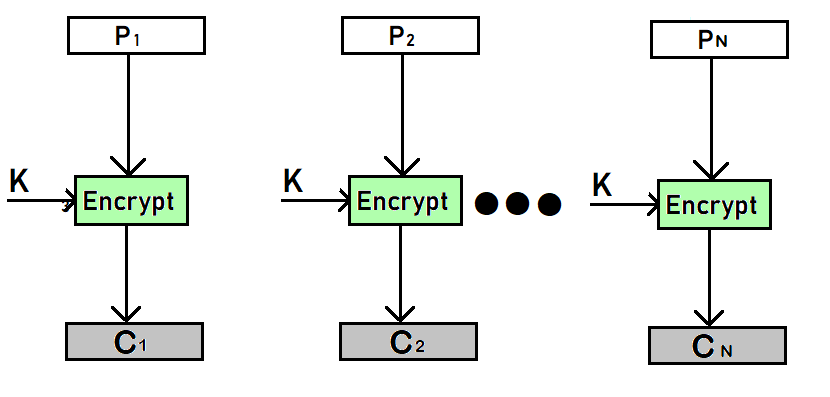

In [92]:
def fetch_image_from_url(url: str) -> Image.Image:
    """
    Download an image from a URL and return it as a PIL Image in RGB mode.
    """
    response = requests.get(url)
    response.raise_for_status()

    img = Image.open(io.BytesIO(response.content))
    # Convert to RGB to ensure consistent 3-channel image
    img = img.convert("RGB")
    return img

def encrypt_image_ecb(img: Image.Image, key: bytes) -> Image.Image:
    # Convert image to raw bytes (RGB channels)
    img_array = np.array(img)
    original_shape = img_array.shape  # (height, width, 3)
    raw_bytes = img_array.tobytes()

    # Pad to multiple of AES block size
    padded = pad(raw_bytes, blocksize)

    # Encrypt
    encrypted = ecb_encrypt.encrypt(padded)

    # Truncate to original length so we can reshape back
    encrypted = encrypted[:len(raw_bytes)]

    # Convert encrypted bytes back to numpy array with the same shape
    encrypted_array = np.frombuffer(encrypted, dtype=np.uint8)
    encrypted_array = encrypted_array.reshape(original_shape)

    # Create image from encrypted data
    encrypted_img = Image.fromarray(encrypted_array, mode="RGB")
    return encrypted_img

def encrypt_image_cbc(img: Image.Image, key: bytes) -> Image.Image:
    # Convert image to raw bytes (RGB channels)
    img_array = np.array(img)
    original_shape = img_array.shape  # (height, width, 3)
    raw_bytes = img_array.tobytes()
    iv = get_random_bytes(16)
    # Pad to multiple of AES block size
    block_size = 16
    padded = pad(raw_bytes, blocksize)
    # Encrypt
    encrypted = cbc_encrypt.encrypt(padded)

    # Truncate to original length so we can reshape back
    encrypted = encrypted[:len(raw_bytes)]

    # Convert encrypted bytes back to numpy array with the same shape
    encrypted_array = np.frombuffer(encrypted, dtype=np.uint8)
    encrypted_array = encrypted_array.reshape(original_shape)

    # Create image from encrypted data
    encrypted_img = Image.fromarray(encrypted_array, mode="RGB")
    return encrypted_img


def display_original_and_encrypted(original: Image.Image, encrypted: Image.Image, title_prefix: str = "", mode: str = ""):
    """
    Display original and encrypted images side by side using matplotlib.
    """
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.axis("off")
    plt.title(f"{title_prefix}Original")

    plt.subplot(1, 2, 2)
    plt.imshow(encrypted)
    plt.axis("off")
    plt.title(f"{title_prefix}Encrypted (AES-{mode})")

    plt.tight_layout()
    plt.show()


def encrypt_from_url(url: str):
    # 1. Fetch image
    img = fetch_image_from_url(url)

    # 2. Generate a random 16-byte key (AES-128)
    key = get_random_bytes(16)

    # 3. Encrypt the image
    encrypted_img_ecb = encrypt_image_ecb(img, key) 
    encrypted_img_cbc = encrypt_image_cbc(img, key)
    # 4. Display both
    display_original_and_encrypted(img, encrypted_img_ecb, title_prefix="Image: ",mode="ECB")
    display_original_and_encrypted(img, encrypted_img_cbc, title_prefix="Image: ",mode="CBC")




### Task 2.1 
1. Find an image online that uses many colours and of many objects, such as a landscape. Copy the url and use the encrypt_from_url helper function to view the encrypted image. The URL is input as a string.
2. Now repeat the exercise for a simplistic image: it should have few colours (ideally 2) and be very structured, such as a brand logo. What do you observe?
3. Write a function called encrypt_image_cbc that takes as input an image and encrypts it under AES-CBC mode. Repeat 1 and 2 with AES-CBC. What's different?

SOLUTION: 
1. Encryption of a landscape looks random!
2. Encryption of structured image is not random, you can see what is encrypted.
3. AES-CBC makes the logo look random too.

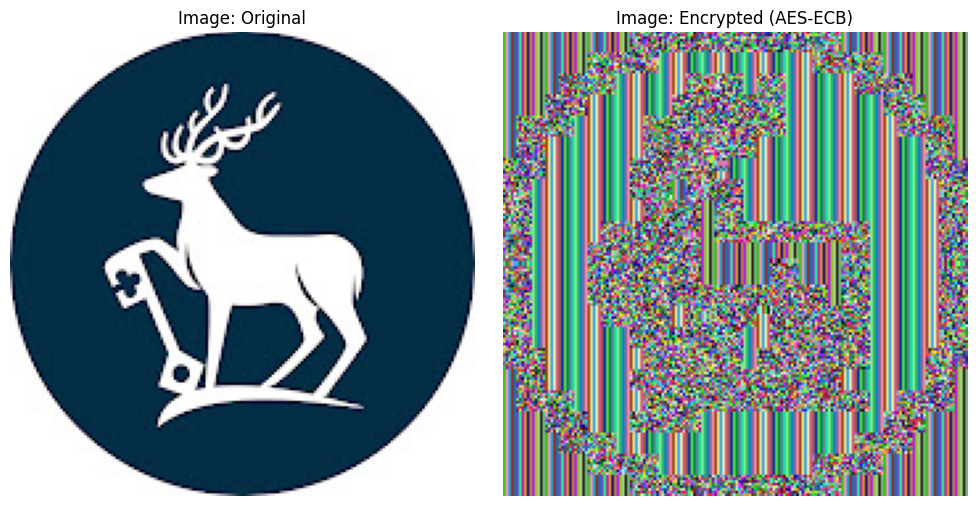

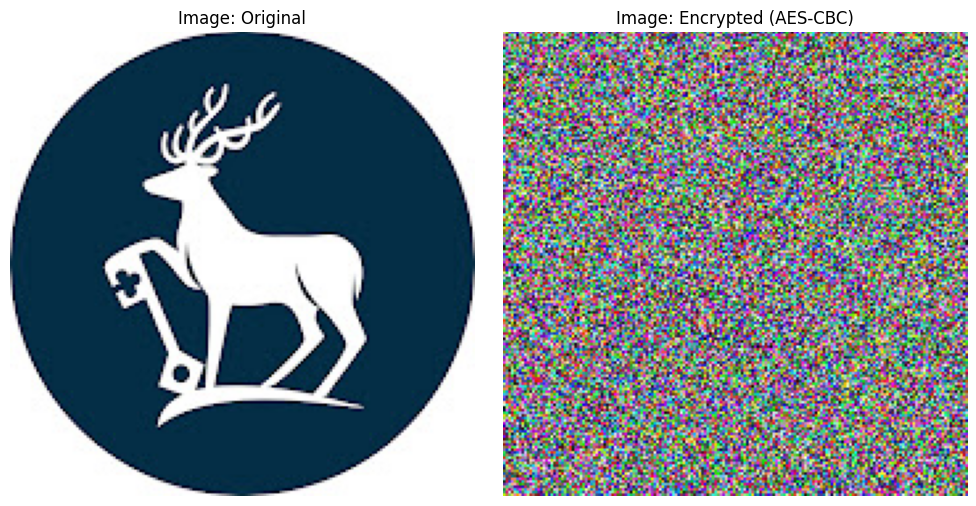

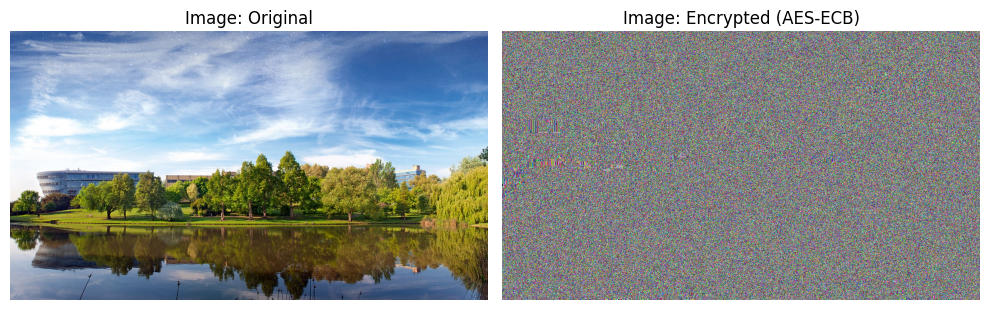

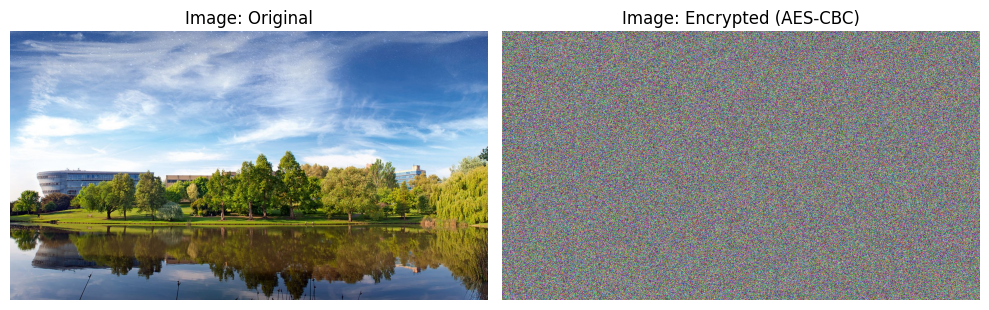

In [93]:
logo = "https://yt3.googleusercontent.com/Sub_LfN7CrxpEYWF9xfW_Jrs9NSJwI9k4RhVM2A6K1j64hAqlbhSuIt_pk24bM23LAhjWtmD=s176-c-k-c0x00ffffff-no-rj-mo"  # replace with your image URL
landscape = "https://www.surrey.ac.uk/sites/default/files/styles/image_gallery/public/2023-05/stag-hill-lake-media.jpg?itok=aNjGlJLH"
encrypt_from_url(logo)
encrypt_from_url(landscape)

## Task 3: Integrity Attack on CBC-mode
In this question you’ll learn how an attacker can manipulate ciphertext in CBC mode to alter the decrypted message. We’ll focus on how flipping bits in the ciphertext can change the corresponding plaintext when decrypted. To achieve this, you will:

1. Create an encryption of "User=Jack;Salary=20000;Role=User" using AES in CBC mode.
2. Modify the ciphertext so that the salary is now 60000.

In [94]:
blocklength = 16
key = get_random_bytes(blocklength)
iv = get_random_bytes(blocklength)
cipher = AES.new(key, AES.MODE_CBC, iv)

### Task 3.1
Create a ciphertext of the message "User=Jack;Salary=20000;Role=User". Check that it sucessfully decrypts. 

In [95]:
#TASK 3.1 SOLUTION 
msg = b"User=Jack;Salary=20000;Role=User" 
ciphertext = cipher.encrypt(pad(msg, blocklength))
print("Original plaintext:", msg)

Original plaintext: b'User=Jack;Salary=20000;Role=User'


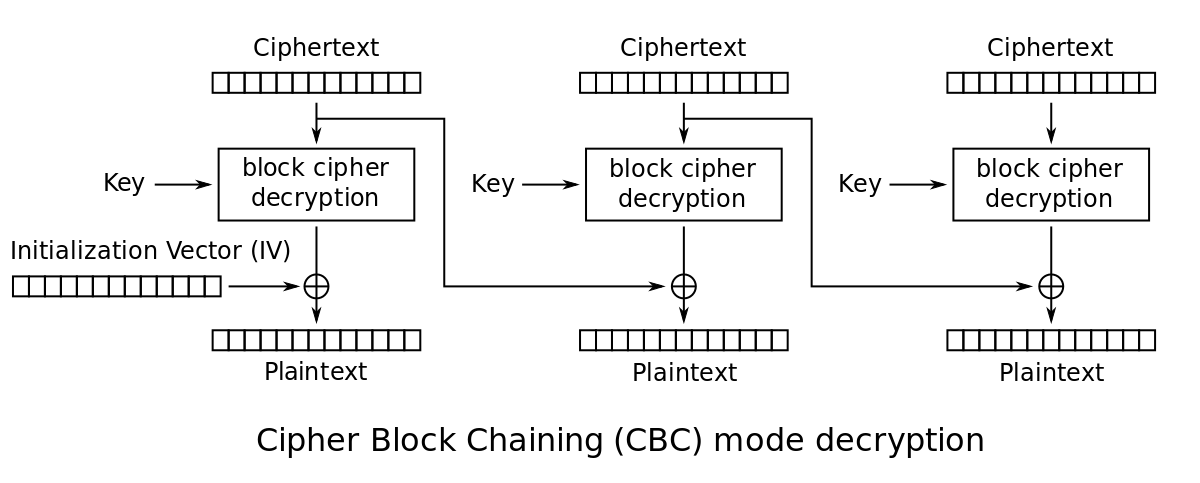

Examine the depiction of CBC mode in the picture above. We see that each plaintext block is XOR’d with the previous ciphertext block before being encrypted. This chaining introduces dependencies between blocks, which is good for confidentiality, but can also be exploited for integrity attacks. So, let's do exactly this.

The general attack is shown in the lecture slides, but let's look at a concrete example: 
1. A message M is extended by padding, and split into blocks. Let's call this the plaintext P, split into blocks P1||P2||P3. Here, || is concatentation.
2. We then Encrypt P = P1||P2||P3 to a ciphertext C = C1||C2||C3.
3. Let's say we want to change C2 to decrypt to something other than P2. Let's call this P4. We examine how P2 is decrypted from the diagram and see that P2 = C1 ⊕ Decrypt(K,C2). So, to replace P2 with P4, we need to modify C1 or C2. We will modify C1.
4. To change P2 -> P4, we need to alter C1 such that it 'removes' P2, and 'adds' P4. To remove P2 we can simply XOR it to C1 (since C2 already contains an XOR of P2, this will cancel it out). To add P4, we can also simply XOR it. Thus we modify C1 to become C1' = C1 ⊕ P2 ⊕ P4.
5. Decrypting the ciphertext C1'||C2||C3 will result in the plaintext ??||P4||P3.
### Question 3.1: 
Why don't we modify C2?
### Solution 3.1: 
Because it goes through a decryption, so we can't control how it will impact the final message.
### Question 3.2: 
Can we say what the value of ?? will be?
### Solution 3.2: 
No, it will be nonsense because it will go through a decryption, and it is computationally infeasible to predict the output of this step.

### Task 3.2: 
Now it's your turn. Implement the described attack on the encryption from Task 3.1, to change Jack's salary to 60000. We can see that "20000" will appear in the second block, so we will need to do byte-wise XOR for each byte in block 1 (indexed from 0). The function for this is the ^ symbol. e.g. A[i] = B[j] ^ C[k] 

In [96]:
#SOLUTION

ct = bytearray(ciphertext)
target_old = b"=20000;Role=User" #for simplicity we replace the entire block, even though we want to change only one character
target_new = b"=60000;Role=User"

for i in range(blocklength):
    ct[i] ^= target_old[i] ^ target_new[i]
    
modified_ciphertext = bytes(ct)
cipher2 = AES.new(key, AES.MODE_CBC, iv)
decrypted = unpad(cipher2.decrypt(modified_ciphertext), blocklength)
print("Modified plaintext:", decrypted)

Modified plaintext: b'\xc4\xa7\xd6X\xac\xc2*\t\x17,!\xc9\x1344\x00=60000;Role=User'


Notice the first part of the plaintext is unreadable. This is a consequence of the attack we used, and is expected!

### 4.  CBC robustness against errors


### Task 4.1
Create a ciphertext of r3speech given here. Check that your ciphertext sucessfully decrypts and gives back the original plaintext. 

In [97]:
r3speech = b"Now is the winter of our discontent Made glorious summer by this sun of York; And all the clouds that lour'd upon our house In the deep bosom of the ocean buried. Now are our brows bound with victorious wreaths; Our bruised arms hung up for monuments; Our stern alarums changed to merry meetings, Our dreadful marches to delightful measures. Gloucester"


In [98]:
#TASK 4.1 SOLUTION 
blocklength = 16
key = get_random_bytes(blocklength)
iv = get_random_bytes(blocklength)
cipher = AES.new(key, AES.MODE_CBC, iv)
cipher2 = AES.new(key, AES.MODE_CBC, iv)

ciphertext = cipher.encrypt(pad(r3speech, blocklength))

decrypted = unpad(cipher2.decrypt(ciphertext), blocklength)

print("Original plaintext:\n", r3speech)
print("\nDecrypted encrypted plaintext:\n", decrypted)

Original plaintext:
 b"Now is the winter of our discontent Made glorious summer by this sun of York; And all the clouds that lour'd upon our house In the deep bosom of the ocean buried. Now are our brows bound with victorious wreaths; Our bruised arms hung up for monuments; Our stern alarums changed to merry meetings, Our dreadful marches to delightful measures. Gloucester"

Decrypted encrypted plaintext:
 b"Now is the winter of our discontent Made glorious summer by this sun of York; And all the clouds that lour'd upon our house In the deep bosom of the ocean buried. Now are our brows bound with victorious wreaths; Our bruised arms hung up for monuments; Our stern alarums changed to merry meetings, Our dreadful marches to delightful measures. Gloucester"


### Task 4.2: 
Following encryption, corrupt (i.e. change) byte 190 of the ciphertext, and then decrypt the resulting corrupted ciphertext.  What impact do you expect to see on the plaintext?

SOLUTION:  As expected we see the corrupted byte has been changed, and also the entire previous block.  The rest of the text is uncorrupted.

In [99]:
#TASK 4.2 SOLUTION 

cipher = AES.new(key, AES.MODE_CBC, iv)
cipher2 = AES.new(key, AES.MODE_CBC, iv)

ciphertext = cipher.encrypt(pad(r3speech, blocklength))

cipherarray = bytearray(ciphertext)
cipherarray[190] = 100
corr_ciphertext = bytes(cipherarray)

decrypted = unpad(cipher2.decrypt(corr_ciphertext), blocklength)

print("\nDecrypted corrupted encrypted plaintext:\n", decrypted)




Decrypted corrupted encrypted plaintext:
 b"Now is the winter of our discontent Made glorious summer by this sun of York; And all the clouds that lour'd upon our house In the deep bosom of the ocean buried. Now are our b\x99\xcc\x07\x89\xd0\x0b\xe1\x9a\xca\xb4\x8e\xa1hd$\xc0victorious wredths; Our bruised arms hung up for monuments; Our stern alarums changed to merry meetings, Our dreadful marches to delightful measures. Gloucester"


### Task 4.3
Now try "decrypting" r3speech (i.e. apply the decryption function) and then encrypting the result.  What do you obtain?  There is a critical difference with the original r3speech, can you explain why this has occurred?

SOLUTION:  This has occurred because the decrypted data was padded when it came to be encrypted, this led to an additional padding block being added, resulting in an additional encrypted block.

In [100]:
#TASK 4.3 SOLUTION 

cipher = AES.new(key, AES.MODE_CBC, iv)
cipher2 = AES.new(key, AES.MODE_CBC, iv)

decrypted2 = cipher2.decrypt(r3speech)

restored = cipher.encrypt(pad(decrypted2, blocklength))

print("Encrypted decrypted speech:\n", restored)


Encrypted decrypted speech:
 b"Now is the winter of our discontent Made glorious summer by this sun of York; And all the clouds that lour'd upon our house In the deep bosom of the ocean buried. Now are our brows bound with victorious wreaths; Our bruised arms hung up for monuments; Our stern alarums changed to merry meetings, Our dreadful marches to delightful measures. Gloucester7\x18\x12=\xf34\x9eh\xa7%7\xab\xbd\xd9\x81\x8d"


### Task 4.4
Now try "decrypting" r3speech, then corrupt (i.e. change) byte 190, then encrypt the result.  What result do you expect to get?  Can you explain the result that occurs?

SOLUTION:  If a byte is changed within a block in advance of encryption, then that has an impact on all subsequent blocks so that the entire text after the corrupted point is completely different.  This is because if a block is different then the input to the cipher for the next block is different, which means that the subsequent block will also be different.

In [101]:
#TASK 4.4 SOLUTION 

cipher = AES.new(key, AES.MODE_CBC, iv)
cipher2 = AES.new(key, AES.MODE_CBC, iv)

decrypted2 = cipher2.decrypt(r3speech)

cipherarray2 = bytearray(decrypted2)
cipherarray2[190] = 100
corr_decrypted2 = bytes(cipherarray2)

restored = cipher.encrypt(pad(corr_decrypted2, blocklength))

print("Encrypted corrupted decrypted r3speech:\n", restored)


Encrypted corrupted decrypted r3speech:
 b"Now is the winter of our discontent Made glorious summer by this sun of York; And all the clouds that lour'd upon our house In the deep bosom of the ocean buried. Now are our b\xf3#\xdc\x8e \x81,\x9b\xe8\x111\xd2\xe0\xa1\xbe\xd8\x1e`\x9b'\xb2\x88Lr<X\xa0\xbf\x92\xac\xff\x0e\xb1\x03r*-\xb8\xb2Sj\x88\xc8\xff~\xe8\xde\xf92}T\xf1\x1c\xf7\xcf\xd6\x1f\n\xb9\x1b\x92\x84BE\xf0\xda\x10bJ\xb8\x02\x03\x9d\x0f\x93{r\x02eE\xda\xb01[\x9a\xf4\x16^\xd5\x1cT\x8b\x14\x84#\x84\x83~\xf8z\xe5!\x82\xca\xa6/*\xbb\xab\xff\xa0\x9a\xeb\x00\xe6\xff\x921\xec*\xd7\xaa|!\xad\x93QYC\xd7\x17\xa6\xd37\x8f\x85xD\x1d\xe3\xb1\xc0\xf6\xf4\x95aW\xcf~\xc7\x1a\xa2\x07P(P\xe9\x80\xfd\x8f\xa6y3Q\xd7\xc2\xbau\x1cZ\xacMK7\xbd&\xdd+\x8ep\xb9\xcd\xa8\xd6x\x82\xbc\xb5.\t5\x0b"
